In [7]:

import pandas as pd
import os

# Find the uploaded CSV file
csv_files = [f for f in os.listdir("/content") if f.endswith(".csv")]
print("CSV files found:", csv_files)


CSV files found: ['social_media_sentiment_raw.csv']


In [9]:

# Replace this with your actual CSV filename
file_path = "/content/social_media_sentiment_raw.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Number of rows: 2260
Number of columns: 13

Column names:
['post_id', 'timestamp', 'platform', 'user', 'followers_count', 'verified', 'text', 'hashtags', 'country', 'likes', 'retweets_shares', 'comments', 'sentiment']

First 5 rows:


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


In [10]:

# 1. Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Column names and data types
print("\n--- Data types ---")
print(df.dtypes)

# 3. Missing values in each column
print("\n--- Missing values ---")
print(df.isnull().sum())

# 4. Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Duplicate post IDs
print("Duplicate post IDs:", df["post_id"].duplicated().sum())

# 7. Summary statistics for numeric columns
print("\n--- Numerical summary ---")
display(df.describe())

# 8. Categories in important columns
print("\n--- Platforms ---")
print(df["platform"].value_counts(dropna=False))

print("\n--- Sentiment labels ---")
print(df["sentiment"].value_counts(dropna=False))

print("\n--- Countries ---")
print(df["country"].value_counts(dropna=False))


Rows: 2260
Columns: 13

--- Data types ---
post_id             object
timestamp           object
platform            object
user                object
followers_count     object
verified            object
text                object
hashtags            object
country             object
likes                int64
retweets_shares      int64
comments           float64
sentiment           object
dtype: object

--- Missing values ---
post_id              0
timestamp            0
platform             0
user                 0
followers_count     90
verified            44
text                 0
hashtags           788
country            126
likes                0
retweets_shares      0
comments            46
sentiment           33
dtype: int64

Total missing values: 1127

Duplicate rows: 44
Duplicate post IDs: 60

--- Numerical summary ---


,likes,retweets_shares,comments
count,2260.00000,2260.000000,2214.000000
mean,35.94646,6.617699,3.448509
std,16.56231,4.721631,2.745874
min,-1.00000,0.000000,0.000000
25%,25.00000,3.000000,1.000000
50%,33.00000,6.000000,3.000000
75%,44.00000,9.000000,5.000000
max,126.00000,37.000000,20.000000



--- Platforms ---
platform
Twitter      691
Instagram    561
TikTok       357
Facebook     352
LinkedIn     118
TWITTER       54
INSTAGRAM     53
TIKTOK        41
FACEBOOK      27
LINKEDIN       6
Name: count, dtype: int64

--- Sentiment labels ---
sentiment
Positive    907
Neutral     675
Negative    645
NaN          33
Name: count, dtype: int64

--- Countries ---
country
USA               433
India             367
UK                202
Canada            164
Australia         156
Germany           143
NaN               126
UAE               110
France            104
Japan             101
Brazil            101
South Africa       78
Mexico             49
usa                33
india              22
uk                 15
canada             12
australia           8
uae                 7
brazil              6
germany             6
japan               5
france              4
south africa        4
mexico              4
Name: count, dtype: int64


In [11]:

# Check unusual values in followers_count
print("Sample follower counts:")
print(df["followers_count"].dropna().astype(str).unique()[:20])

# Check invalid or unusual likes
print("\nRows where likes are negative:")
display(df[df["likes"] < 0][
    ["post_id", "platform", "likes", "text"]
])

# Inspect duplicate post IDs
duplicate_ids = df[df["post_id"].duplicated(keep=False)]
print("\nRows sharing post IDs:", len(duplicate_ids))
display(
    duplicate_ids.sort_values("post_id")[
        ["post_id", "platform", "timestamp", "text",
         "likes", "comments", "sentiment"]
    ].head(20)
)

# Inspect missing hashtags
print("\nExamples with missing hashtags:")
display(df[df["hashtags"].isna()][
    ["platform", "text", "hashtags"]
].head(10))

# Check sentiment labels, including missing values
print("\nSentiment values:")
print(df["sentiment"].value_counts(dropna=False))


Sample follower counts:
['668.0' '54.0' '559.0' '3123.0' '549.0' '2459.0' '7303.0' '6580.0' '38.0'
 '200.0' '2659.0' '5227.0' '6465.0' '6234.0' '7903.0' '399' '2106.0'
 '439.0' '1041.0' '2144.0']

Rows where likes are negative:


,post_id,platform,likes,text
157,P101989,Instagram,-1,"Attended a campaign session today, some intere..."
196,P100866,TikTok,-1,"Just checked out the new event feature, still ..."
1205,P100777,Facebook,-1,This product launch exceeded all my expectatio...
1495,P100121,Twitter,-1,"Best app experience ever, highly recommend to ..."
1566,P100938,Twitter,-1,This product issue has been ignored for weeks ...
1738,P102158,Instagram,-1,Worst product experience I've had in a long ti...
1948,P100621,Twitter,-1,"Absolutely loving the new event update, this i..."
2135,P100077,Twitter,-1,"Terrible customer support regarding community,..."



Rows sharing post IDs: 120


,post_id,platform,timestamp,text,likes,comments,sentiment
265,P100002,Facebook,2023-06-13 15:23:12,"Best platform experience ever, highly recommen...",19,0.0,Positive
1366,P100002,Facebook,2023-06-13 15:23:12,"Best platform experience ever, highly recommen...",19,0.0,Positive
399,P100007,TWITTER,2024-01-24 09:49:42,"Just checked out the new policy feature, still...",32,1.0,Neutral
1777,P100007,Twitter,2024-01-24 09:49:42,"Just checked out the new policy feature, still...",32,1.0,Neutral
323,P100054,Twitter,2023-08-13 06:24:13,"Attended a event session today, some interesti...",47,NaN,Neutral
180,P100054,Twitter,2023-08-13 06:24:13,"Attended a event session today, some interesti...",47,NaN,Neutral
559,P100060,Twitter,2024-12-13 00:42:40,"Absolutely loving the new campaign update, thi...",41,2.0,Positive
1208,P100060,Twitter,2024-12-13 00:42:40,"Absolutely loving the new campaign update, thi...",41,2.0,Positive
945,P100110,LinkedIn,2024-10-10 03:39:33,"Best policy experience ever, highly recommend ...",21,3.0,Positive
2041,P100110,LinkedIn,2024-10-10 03:39:33,"Best policy experience ever, highly recommend ...",21,3.0,Positive



Examples with missing hashtags:


,platform,text,hashtags
1,Facebook,This event launch exceeded all my expectations...,NaN
4,LinkedIn,This product launch exceeded all my expectatio...,NaN
5,Twitter,"Not happy at all about the service changes, fe...",NaN
8,Twitter,"Can't stop smiling after that campaign event, ...",NaN
16,Instagram,"Terrible customer support regarding campaign, ...",NaN
20,Twitter,"Best campaign experience ever, highly recommen...",NaN
23,TikTok,Worst policy experience I've had in a long tim...,NaN
28,Twitter,"Sharing an article about event, worth a look.",NaN
31,TikTok,"Terrible customer support regarding campaign, ...",NaN
32,TWITTER,This release issue has been ignored for weeks ...,NaN



Sentiment values:
sentiment
Positive    907
Neutral     675
Negative    645
NaN          33
Name: count, dtype: int64


In [12]:

import pandas as pd

# Preserve the original dataset and create a working copy
clean_df = df.copy()

# 1. Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# 2. Standardize text categories
for col in ["platform", "country", "sentiment"]:
    clean_df[col] = clean_df[col].str.strip().str.title()

# 3. Convert numeric columns safely
numeric_cols = [
    "followers_count", "likes", "retweets_shares", "comments"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# 4. Treat negative engagement counts as invalid
engagement_cols = ["likes", "retweets_shares", "comments"]

for col in engagement_cols:
    clean_df.loc[clean_df[col] < 0, col] = float("nan")

# Follower counts should not be negative either
clean_df.loc[clean_df["followers_count"] < 0, "followers_count"] = float("nan")

# 5. Convert timestamp to datetime
clean_df["timestamp"] = pd.to_datetime(
    clean_df["timestamp"], errors="coerce"
)

# 6. Check duplicate post IDs after exact duplicates are removed
print("Original rows:", len(df))
print("Rows after exact duplicate removal:", len(clean_df))
print("Remaining repeated post IDs:",
      clean_df["post_id"].duplicated().sum())

print("\nMissing values after cleaning:")
print(clean_df.isna().sum())

print("\nData types:")
print(clean_df.dtypes)

print("\nUpdated platform counts:")
print(clean_df["platform"].value_counts(dropna=False))


Original rows: 2260
Rows after exact duplicate removal: 2216
Remaining repeated post IDs: 16

Missing values after cleaning:
post_id              0
timestamp            0
platform             0
user                 0
followers_count    155
verified            44
text                 0
hashtags           768
country             82
likes                8
retweets_shares      0
comments            46
sentiment           33
dtype: int64

Data types:
post_id                    object
timestamp          datetime64[ns]
platform                   object
user                       object
followers_count           float64
verified                   object
text                       object
hashtags                   object
country                    object
likes                     float64
retweets_shares           float64
comments                  float64
sentiment                  object
dtype: object

Updated platform counts:
platform
Twitter      734
Instagram    601
Tiktok       391
Facebook

In [13]:

# Count unique versions of each post ID
id_check = (
    clean_df.groupby("post_id", dropna=False)
    .agg(
        row_count=("post_id", "size"),
        unique_texts=("text", "nunique"),
        unique_timestamps=("timestamp", "nunique"),
        unique_platforms=("platform", "nunique")
    )
    .reset_index()
)

conflicts = id_check[
    (id_check["unique_texts"] > 1) |
    (id_check["unique_timestamps"] > 1) |
    (id_check["unique_platforms"] > 1)
]

print("Post IDs with conflicting text, timestamp, or platform:",
      len(conflicts))
display(conflicts.head(20))


Post IDs with conflicting text, timestamp, or platform: 0


,post_id,row_count,unique_texts,unique_timestamps,unique_platforms


In [14]:

# Keep the first record for each post ID
clean_df = clean_df.drop_duplicates(subset="post_id", keep="first").copy()

print("Final cleaned row count:", len(clean_df))
print("Unique post IDs:", clean_df["post_id"].nunique())
print("Remaining duplicate IDs:", clean_df["post_id"].duplicated().sum())

print("\nMissing values:")
print(clean_df.isna().sum())


Final cleaned row count: 2200
Unique post IDs: 2200
Remaining duplicate IDs: 0

Missing values:
post_id              0
timestamp            0
platform             0
user                 0
followers_count    153
verified            44
text                 0
hashtags           762
country             66
likes                8
retweets_shares      0
comments            44
sentiment           33
dtype: int64


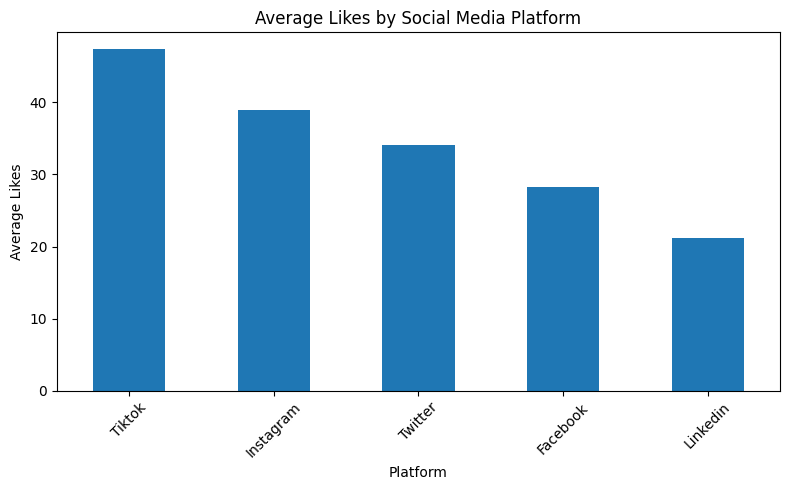

Average likes by platform:
platform
Tiktok       47.35
Instagram    39.01
Twitter      34.04
Facebook     28.32
Linkedin     21.22
Name: likes, dtype: float64


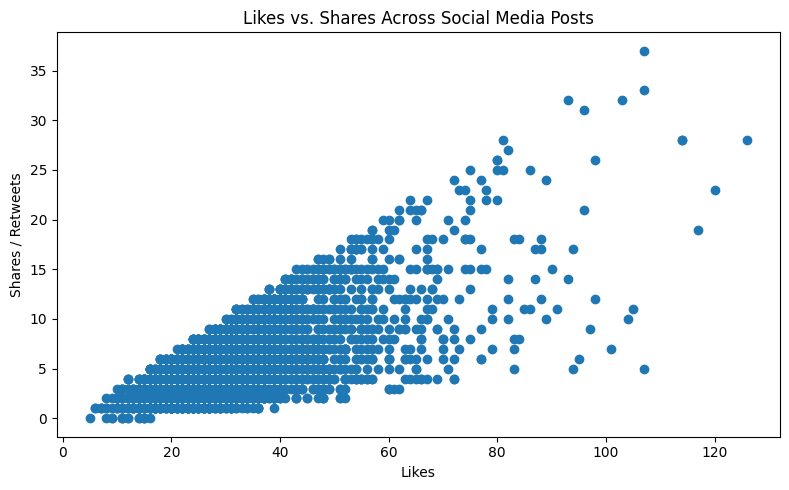

Correlation between likes and shares: 0.682


In [15]:

import matplotlib.pyplot as plt

# Chart 1: Average likes by platform
avg_likes = (
    clean_df.groupby("platform")["likes"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
avg_likes.plot(kind="bar")
plt.title("Average Likes by Social Media Platform")
plt.xlabel("Platform")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average likes by platform:")
print(avg_likes.round(2))

# Chart 2: Likes vs. shares
plot_df = clean_df.dropna(subset=["likes", "retweets_shares"])

plt.figure(figsize=(8, 5))
plt.scatter(plot_df["likes"], plot_df["retweets_shares"])
plt.title("Likes vs. Shares Across Social Media Posts")
plt.xlabel("Likes")
plt.ylabel("Shares / Retweets")
plt.tight_layout()
plt.show()

print(
    "Correlation between likes and shares:",
    round(plot_df["likes"].corr(plot_df["retweets_shares"]), 3)
)


In [16]:

import pandas as pd
import time
import os

base_df = clean_df.copy()
results = []

for target_rows in [2000, 20000, 200000]:
    repeats = (target_rows // len(base_df)) + 1

    test_df = pd.concat(
        [base_df] * repeats,
        ignore_index=True
    ).iloc[:target_rows].copy()

    # Label the experiment so repeated records aren't mistaken
    # for new real-world observations.
    test_df["record_source"] = "Repeated data for scaling experiment"

    file_path = f"/content/scaling_test_{target_rows}.csv"

    start = time.perf_counter()
    test_df.to_csv(file_path, index=False)
    write_seconds = time.perf_counter() - start

    file_size_mb = os.path.getsize(file_path) / (1024 * 1024)

    start = time.perf_counter()
    summary = test_df.groupby("platform")[
        ["likes", "comments", "retweets_shares"]
    ].mean()
    analysis_seconds = time.perf_counter() - start

    results.append({
        "Rows": target_rows,
        "File Size (MB)": round(file_size_mb, 3),
        "CSV Write Time (seconds)": round(write_seconds, 4),
        "Analysis Time (seconds)": round(analysis_seconds, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)


,Rows,File Size (MB),CSV Write Time (seconds),Analysis Time (seconds)
0,2000,0.370,0.0485,0.0030
1,20000,3.703,0.4535,0.0063
2,200000,37.032,3.1535,0.0206
